In [1]:
import sys,os
sys.path.append('../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['*','p','o','h','^']
_linestyles = ['-','--','dotted']
plot_id = 0

layer_ids=array([0])
layer_ids=array([0])


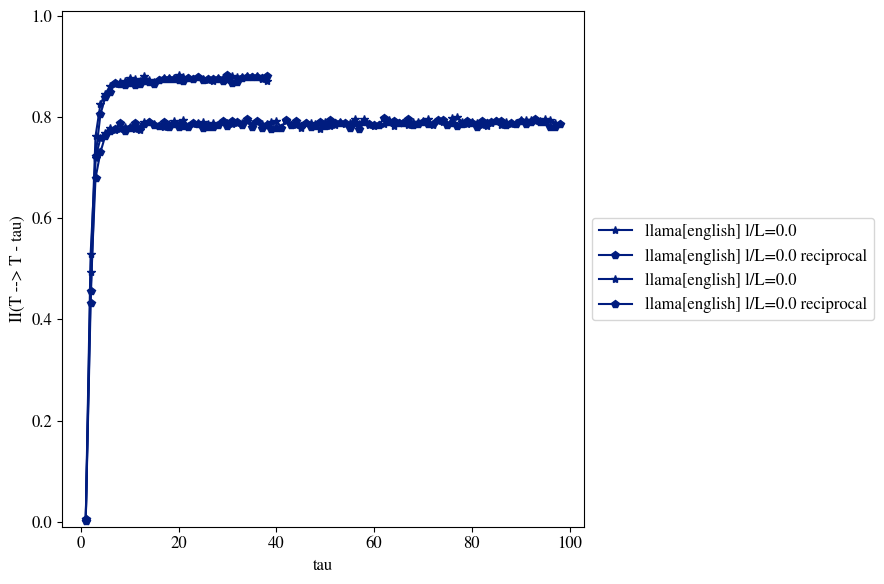

In [37]:
models = [
          # 'deepseek',
          'llama',
          ]
depths = {"deepseek":61,
          "llama":32}
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

mask = 2
min_token_lengths = [40,100]
k = 10
Nbits = 1
seed_list = np.arange(10,dtype=int) 
n_tokens = 1


figsfolder = f'results/figs/'
os.makedirs(figsfolder,exist_ok=True)
fig,ax = plt.subplots(1,1,
                      figsize=(9,6),
                      # constrained_layout=True,
                      )
for min_token_length_id,min_token_length in enumerate(min_token_lengths):
  n_loaded_tokens = min_token_length - mask
  for model_id,model in enumerate(models):
    relative_depths = np.array([.001])
    layer_ids = (relative_depths * depths[model]).astype(int)
    print(f'{layer_ids=}')
    for r_id,r in enumerate(relative_depths):
      for language_pair_id, language_pair in enumerate(language_pairs):
        for language_id,language in enumerate(language_pair[:1]):
          IIs = np.zeros(shape=(len(seed_list),2,depths[model],n_loaded_tokens))
          for seed_id,seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                      )
            IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
            IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
          ax.plot(range(1,n_loaded_tokens+1),
                    IIs[:,0,layer_ids[r_id],:].mean(axis=0),
                    linestyle=_linestyles[language_id],
                    label=f'{model}[{language}] l/L={round(relative_depths[r_id],2)}',
                    marker=markers[0],
                    color=colors[r_id%len(colors)],)
          ax.plot(range(1,n_loaded_tokens+1),
                    IIs[:,1,layer_ids[r_id],:].mean(axis=0),
                    linestyle=_linestyles[language_id],
                    label=f'{model}[{language}] l/L={round(relative_depths[r_id],2)} reciprocal',
                    marker=markers[1],
                    color=colors[r_id%len(colors)],)

ax.set_xlabel('tau')
ax.set_ylabel('II(T --> T - tau)')
ax.set_ylim(-0.01,1.01)
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig.savefig(f'{figsfolder}future-past-II.pdf',bbox_inches='tight')

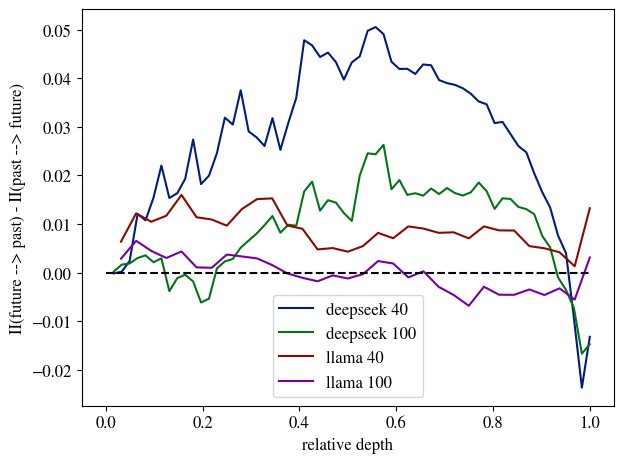

In [33]:
fig,ax = plt.subplots(1)

# max_tokens = N
min_token_lengths = [40,100]

for model_id,model in enumerate(models):
  for min_token_length_id,min_token_length in enumerate(min_token_lengths):
    n_loaded_tokens = min_token_length - mask
    for language_pair_id, language_pair in enumerate(language_pairs):
      for language_id,language in enumerate(language_pair[:1]):
        IIs = np.zeros(shape=(len(seed_list),2,depths[model],n_loaded_tokens))
        for seed_id,seed in enumerate(seed_list):
          II_folder = makefolder(base=f'./results/santiago/',
                                    modelA=model,
                                    modelB=model,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=language,
                                    mask=mask,
                                    k=k,
                                    Nbits=Nbits,
                                    seed=seed,
                                    )
          IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
          IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
          max_tokens = (n_loaded_tokens+2)//2
          max_tokens = None
        A = IIs[:,0,:,:max_tokens].mean(axis=0).mean(axis=-1) - IIs[:,1,:,:max_tokens].mean(axis=0).mean(axis=-1)
        ax.plot(np.arange(1,depths[model]+1)/depths[model],
                  A,
                  label=f'{model} {min_token_length}',
                  )


ax.set_ylabel('II(future --> past) - II(past --> future)')
ax.set_xlabel('relative depth')
# ax.set_title(f'{min_token_length=}')

ax.hlines(0,0,1,color='black',linestyles='dashed')
ax.legend()
plt.show()